# VLM attention explanations from a raw GQA question

One pretrained SmolVLM-500M, one question, eight methods. The main path performs real inference and attribution. The bundled files supply only the raw image and GQA annotation, not cached results. Install `pip install "vlmprobe[transformers,visualization,notebooks]"` and open this notebook inside a repository checkout. GPU recommended. All target construction and plotting coordinates are visible below.

## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

New Colab checkouts use the reviewed source **gexinh/vlm-probe** at commit
`e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1`. This pins the runtime source for
reproducible execution.

Optional environment settings: VLM_PROBING_REPOSITORY and VLM_PROBING_REF
override that pinned repository and commit; VLM_PROBING_COLAB_DIR changes
the checkout directory (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "gexinh/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get(
        "VLM_PROBING_REF", "e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1"
    )
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


## 1. Image, prompt, generation and full-answer target

We show the model’s generated answer, but explain the fixed annotated answer. Every annotated answer token is teacher-forced and scored with `SequenceLogProb`. This avoids silently treating a whole word as one token. SmolVLM accepts a single processed image tile here; this explicit preprocessing choice reduces runtime and gives one verified spatial grid.

In [1]:
from pathlib import Path
import json
import os
import numpy as np
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from vlmprobe import Prober, ProbeInputs, TokenLayout, SequenceLogProb
from vlmprobe import visualization as viz
import matplotlib.pyplot as plt

# Install: pip install "vlmprobe[transformers,visualization,notebooks]"
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "demos/assets/gqa_samples.json").is_file())
# This manifest contains raw GQA questions/answers and image provenance only.
sample = json.loads((ROOT / "demos/assets/gqa_samples.json").read_text())[0]
image = Image.open(ROOT / "demos/assets/images" / sample["image_path"]).convert("RGB")
question = sample["question"]
answer = sample["answer"]
model_id = os.environ.get("VLM_PROBING_MODEL", "HuggingFaceTB/SmolVLM-500M-Instruct")
device = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
model = AutoModelForImageTextToText.from_pretrained(
    model_id, dtype=torch.float32, attn_implementation="eager",
).to(device).eval()
processor = AutoProcessor.from_pretrained(model_id)
# One image tile keeps this tutorial small and gives one unambiguous patch grid.
processor.image_processor.do_image_splitting = False
processor.image_processor.size = {"longest_edge": model.config.vision_config.image_size}
probe = Prober(model, processor)
messages = [{"role": "user", "content": [
    {"type": "image"}, {"type": "text", "text": question},
]}]
prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
base = probe.prepare(prompt=prompt, image=image, device=device)
with torch.no_grad():
    generated = model.generate(**base.kwargs, max_new_tokens=12, do_sample=False)
print("Question:", question)
print("Generated:", processor.tokenizer.decode(generated[0, base.kwargs["input_ids"].shape[1]:], skip_special_tokens=True))

# Teacher-force the entire annotated answer; never assume an answer is one token.
scored = probe.prepare(prompt=prompt + answer, image=image, device=device)
ids = scored.kwargs["input_ids"]
prefix_length = base.kwargs["input_ids"].shape[1]
assert torch.equal(ids[:, :prefix_length], base.kwargs["input_ids"]), "Check the tokenizer's prompt boundary"
valid = scored.kwargs["attention_mask"].bool()
visual = ids.eq(model.config.image_token_id) & valid
prompt_mask = valid.clone()
prompt_mask[:, prefix_length:] = False
answer_mask = valid & ~prompt_mask
query_mask = torch.zeros_like(valid)
query_mask[:, :-1] = answer_mask[:, 1:]  # Rows predicting the selected answer tokens.
inputs = ProbeInputs(scored.kwargs, TokenLayout(valid, visual, prompt_mask, ids))
metric = SequenceLogProb(answer_mask, reduction="sum")
print("Annotated answer tokens:", processor.tokenizer.convert_ids_to_tokens(ids[answer_mask].tolist()))
print("Input token count:", ids.shape[1], "| visual slots:", int(visual.sum()))
output_dir = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/vlm-attention-tutorial"))
output_dir.mkdir(parents=True, exist_ok=True)


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Question: Is the shirt black or yellow?
Generated:  The shirt is black.
Annotated answer tokens: ['yellow']
Input token count: 83 | visual slots: 64


## 2. Fresh attribution and built-in visualization

ATTATTR modifies attention probabilities; TAM and Beyond use an input path. SmolVLM treats all-zero tiles as padding, so the latter use a real gray image processed with the same prompt/layout. We keep every other native processor field fixed. The map is language-decoder attention over merged visual slots, not a vision-encoder segmentation.

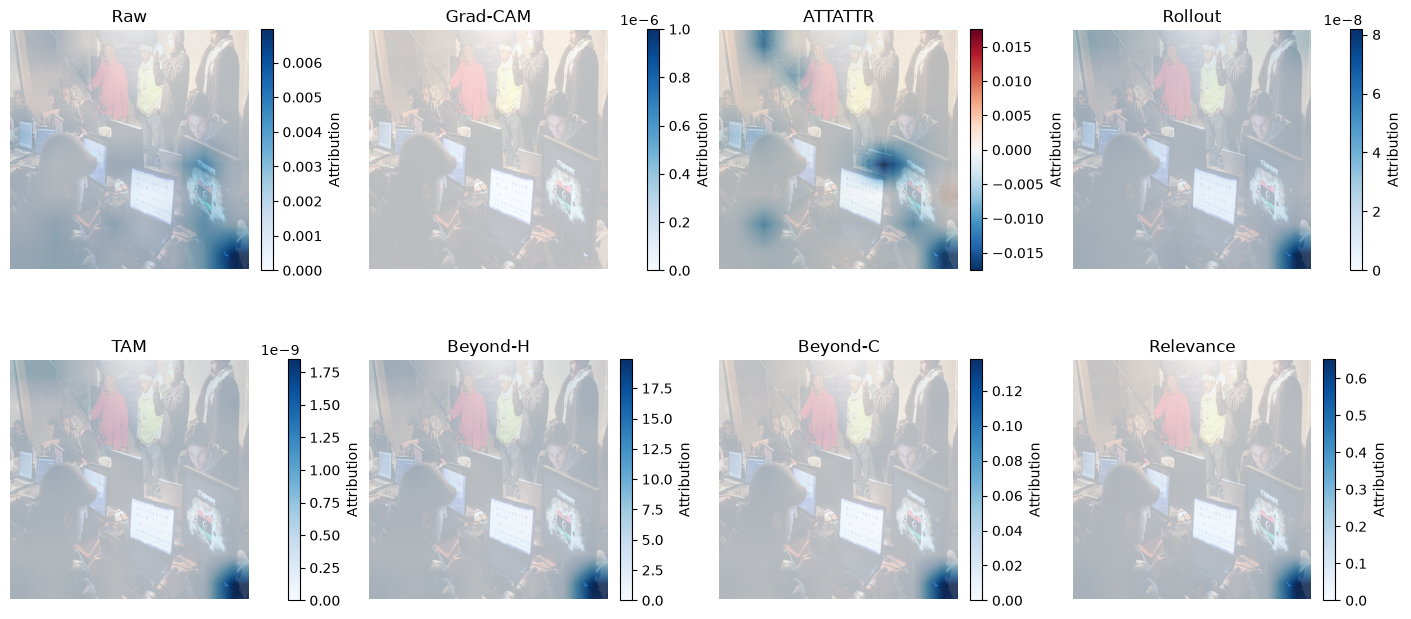

Raw {'entropy': (1, 1, 15, 83), 'concentration': (1, 1, 15, 83), 'max_probability': (1, 1, 15, 83), 'valid_queries': (1, 1, 83), 'group_mass': (1, 1, 15, 83, 2), 'attention': (1, 1, 15, 83, 83)}
Grad-CAM {'cam': (1, 1, 83, 83), 'head_weights': (1, 1, 15, 83), 'query_mask': (1, 83), 'key_mask': (1, 83), 'baseline_score': (1,)}
ATTATTR {'attribution': (1, 1, 15, 83, 83), 'head_attribution': (1, 1, 15), 'token_attribution': (1, 1, 83, 83), 'query_mask': (1, 83), 'key_mask': (1, 83), 'baseline_score': (1,)}
Rollout {'rollout': (1, 83, 83), 'layer_rollouts': (32, 1, 83, 83)}
TAM {'relevance': (1, 83, 83), 'state': (1, 83, 83), 'feedback': (1, 83, 83), 'map': (1, 83, 83), 'query_mask': (1, 83), 'key_mask': (1, 83), 'baseline_score': (1,)}
Beyond-H {'relevance': (1, 83, 83), 'perception': (1, 83, 83), 'feedback': (1, 83, 83), 'layer_perception': (32, 1, 83, 83), 'head_weights': (32, 1, 15), 'map': (1, 83, 83), 'query_mask': (1, 83), 'key_mask': (1, 83), 'baseline_score': (1,)}


Beyond-C {'relevance': (1, 83, 83), 'perception': (1, 83, 83), 'feedback': (1, 83, 83), 'layer_perception': (32, 1, 83, 83), 'token_weights': (32, 1, 83), 'map': (1, 83, 83), 'query_mask': (1, 83), 'key_mask': (1, 83), 'baseline_score': (1,)}
Relevance {'relevance': (1, 83, 83), 'layer_relevance': (32, 1, 83, 83), 'weighted_attention': (32, 1, 83, 83)}


In [2]:
capabilities = probe.describe()["methods"]
last = capabilities["attention.profile"]["sites"][-1]
steps = int(os.environ.get("VLM_PROBING_STEPS", "8"))
# Gray raw image -> native processor. Preserve a real nonzero valid image tile.
gray = Image.new("RGB", image.size, (128, 128, 128))
reference = probe.prepare(prompt=prompt + answer, image=gray, device=device)
assert torch.equal(reference.kwargs["input_ids"], ids)
assert torch.equal(reference.kwargs["pixel_attention_mask"], inputs.kwargs["pixel_attention_mask"])
input_baseline = reference.kwargs["pixel_values"]
results = {
    "Raw": probe.attention.profile(layers=[last], queries=query_mask, include_attention=True).run(inputs),
    "Grad-CAM": probe.attention.grad_cam(layers=[last], queries=query_mask, keys="visual").run(inputs, metric=metric),
    "ATTATTR": probe.attention.attribution(layers=[last], queries=query_mask, keys="visual", steps=steps).run(inputs, metric=metric),
    "Rollout": probe.attention.rollout().run(inputs),
    "TAM": probe.attention.tam(queries=query_mask, keys="visual", steps=steps).run(inputs, metric=metric, baseline=input_baseline),
    "Beyond-H": probe.attention.beyond_intuition(variant="head", queries=query_mask, keys="visual", steps=steps).run(inputs, metric=metric, baseline=input_baseline),
    "Beyond-C": probe.attention.beyond_intuition(variant="token", queries=query_mask, keys="visual", steps=steps).run(inputs, metric=metric, baseline=input_baseline),
    "Relevance": probe.attention.relevance().run(inputs, metric=metric),
}
# The one-tile SmolVLM contract: row-major merged square vision patches.
pixels = inputs.kwargs["pixel_values"]
assert pixels.shape[1] == 1, "Split a multi-tile input into verified separate grids"
patch = model.config.vision_config.patch_size
merge = model.config.scale_factor
grid_shape = (pixels.shape[-2] // patch // merge, pixels.shape[-1] // patch // merge)
visual_positions = visual[0].nonzero().flatten().cpu().tolist()
query_positions = query_mask[0].nonzero().flatten().cpu().tolist()
assert len(visual_positions) == grid_shape[0] * grid_shape[1]
mean = torch.tensor(processor.image_processor.image_mean)[:, None, None]
std = torch.tensor(processor.image_processor.image_std)[:, None, None]
rgb = (pixels[0, 0].detach().cpu() * std + mean).clamp(0, 1)
processed_image = Image.fromarray((rgb.permute(1,2,0).numpy() * 255).astype("uint8"))
fig, axes = viz.plot_attention_comparison(
    processed_image, results, grid_shape=grid_shape, visual_positions=visual_positions,
    query_positions=query_positions, columns=4,
    signed={name: name == "ATTATTR" for name in results},
    image_alpha=0.25, alpha=1.0, shared_scale=False,
)
fig.savefig(output_dir / "vlm-attention-comparison.png", dpi=160, bbox_inches="tight")
plt.show()
for name, result in results.items():
    result.save(output_dir / name.lower())
    print(name, {key: tuple(value.shape) for key, value in result.tensors.items()})


## Reading and adapting the result

`image_alpha=0.25` fades the original image; the measured map stays opaque. Per-method scales preserve signed ATTATTR and avoid implying that different units share a magnitude. Zero maps remain zero. Swapping models changes the loading/chat/geometry setup; method factories keep the same syntax when `describe()` reports support. Qwen3.5 hybrid linear blocks prevent contiguous attention propagation: individual-layer methods remain usable on full-attention blocks, but Rollout/TAM/Beyond/Relevance are not interchangeable there. [Full API and references](../docs/methods/attention_maps.md).